# Week 7 — Segmentasi Citra dengan Thresholding

**Mata kuliah:** Pengolahan Citra dan Visi Komputer  
**Nama:** ................................  
**NIM:** ................................  
**Kelas:** ................................


# Praktikum D1 nomor 1–2 Hubungkan Google Drive dan import library

Library yang digunakan mengikuti modul: OpenCV, NumPy, Matplotlib,
scikit-image, dan K-Means dari scikit-learn.

In [24]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skimage import data
from skimage.segmentation import flood
from pathlib import Path
from collections import deque

plt.rcParams['figure.dpi'] = 100


In [26]:
# Sesuaikan hanya nama file apabila nama di Drive berbeda.
FOLDER = Path('/content/drive/MyDrive/PCVK')
FILES = {
    'gradient': 'gradient.jpg',
    'sudoku': 'sudoku-original.jpg',
    'lena': 'lena_gs_lc2.png',
    'noisy': 'noisy2.png',
    'lily': 'lily.jpg',
    'ktp_sendiri': 'ktp_saya.jpeg',
    'ktp_fulan': 'ktp_fulan.webp',
}
# Jika KTP sendiri juga digunakan pada nomor 7, ganti baris berikut:
# FILES['ktp_fulan'] = FILES['ktp_sendiri']

for label, nama in FILES.items():
    status = 'tersedia' if (FOLDER / nama).is_file() else 'belum ditemukan'
    print(f'{label:12s}: {nama} — {status}')

def baca_citra(label, grayscale=False):
    filename = FOLDER / FILES[label]
    flag = cv.IMREAD_GRAYSCALE if grayscale else cv.IMREAD_COLOR
    img = cv.imread(str(filename), flag)
    if img is None:
        raise FileNotFoundError(
            f'Citra tidak dapat dibaca: {filename}. '
            'Periksa mount Drive dan nama file pada sel konfigurasi.'
        )
    return img

def tampilkan(images, titles, rows=1, cols=None, figsize=(15, 5)):
    # Citra warna yang masuk ke fungsi ini harus sudah dalam format RGB.
    if cols is None:
        cols = int(np.ceil(len(images) / rows))
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        if img.ndim == 2:
            # Rentang tetap agar citra biner hitam/putih ditampilkan dengan benar.
            plt.imshow(img, cmap='gray', vmin=0, vmax=255)
        else:
            plt.imshow(img)
        plt.title(title)
        plt.xticks([])
        plt.yticks([])
    plt.tight_layout()
    plt.show()


gradient    : gradient.jpg — tersedia
sudoku      : sudoku-original.jpg — tersedia
lena        : lena_gs_lc2.png — tersedia
noisy       : noisy2.png — tersedia
lily        : lily.jpg — tersedia
ktp_sendiri : ktp_saya.jpeg — tersedia
ktp_fulan   : ktp_fulan.webp — tersedia


## C.3 Contoh Global Threshold dengan OpenCV



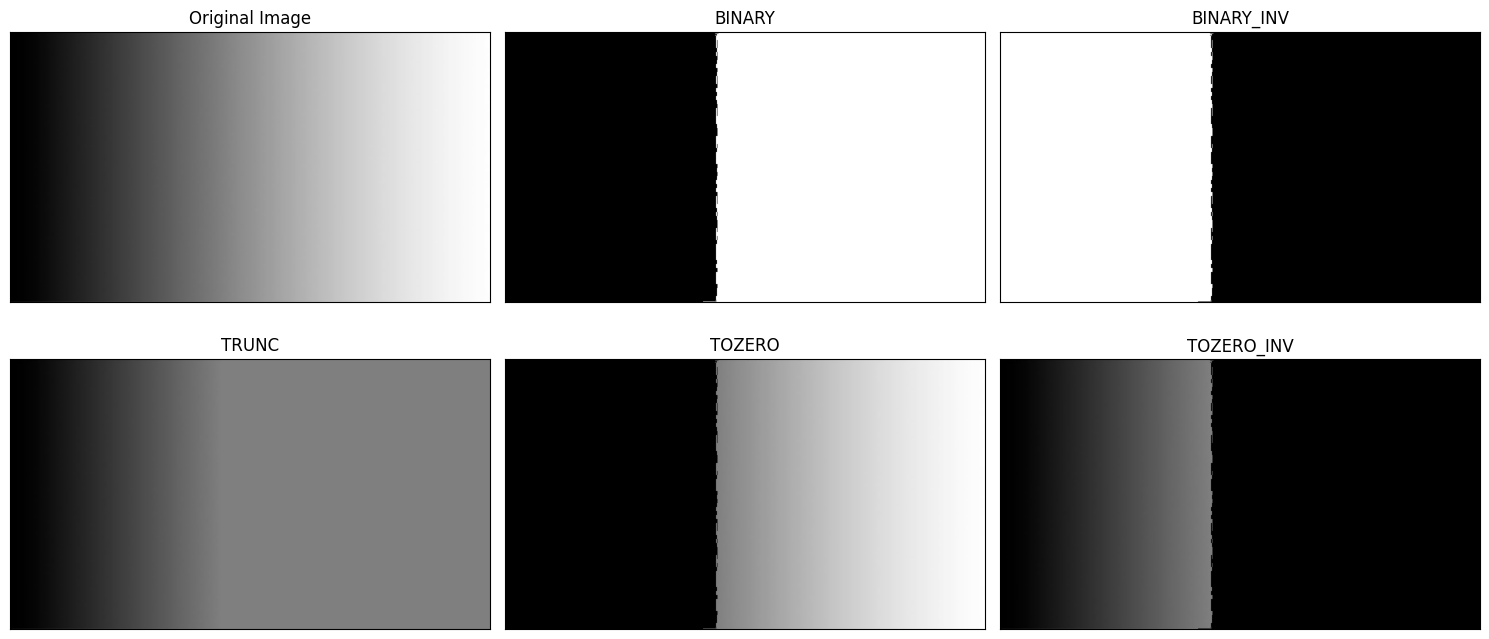

In [27]:
gradient = baca_citra('gradient', grayscale=True)
thresh = 127
maxval = 255

ret, thresh1 = cv.threshold(gradient, thresh, maxval, cv.THRESH_BINARY)
ret, thresh2 = cv.threshold(gradient, thresh, maxval, cv.THRESH_BINARY_INV)
ret, thresh3 = cv.threshold(gradient, thresh, maxval, cv.THRESH_TRUNC)
ret, thresh4 = cv.threshold(gradient, thresh, maxval, cv.THRESH_TOZERO)
ret, thresh5 = cv.threshold(gradient, thresh, maxval, cv.THRESH_TOZERO_INV)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [gradient, thresh1, thresh2, thresh3, thresh4, thresh5]
tampilkan(images, titles, rows=2, cols=3, figsize=(15, 7))


## C.4 Contoh Adaptive Threshold dengan OpenCV


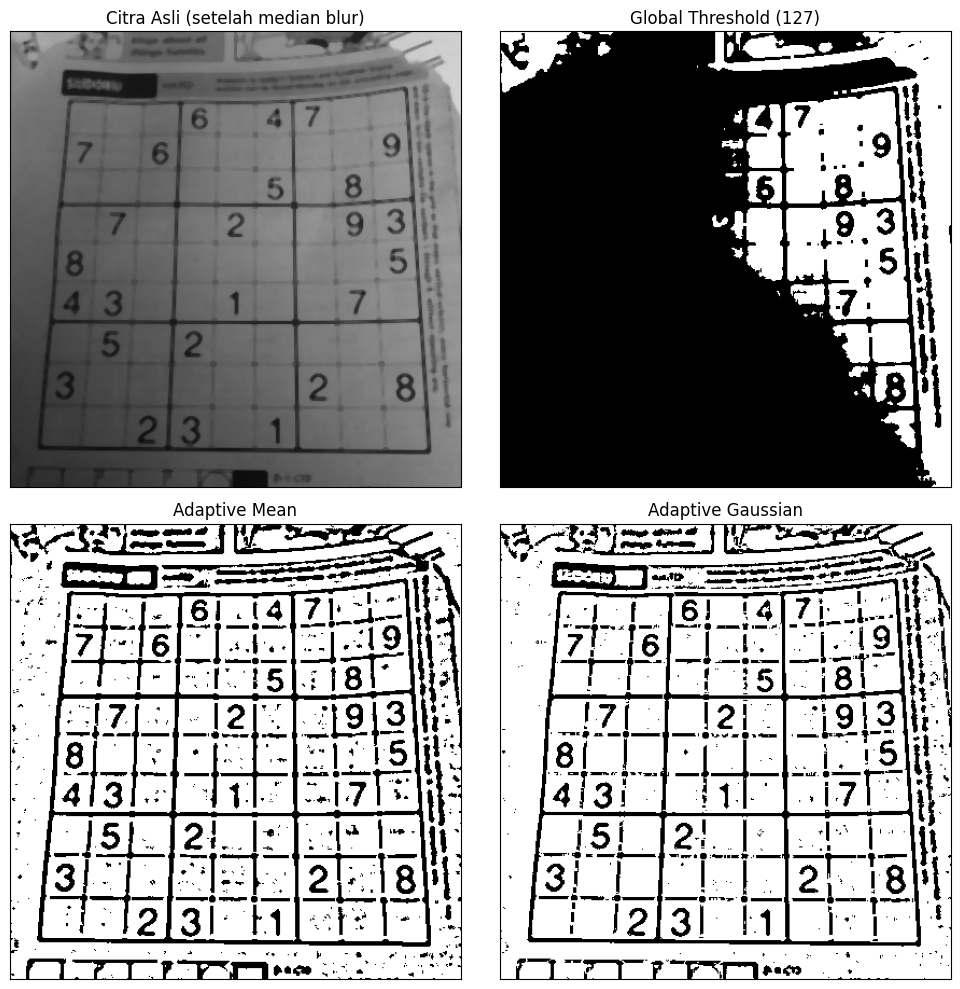

In [28]:
citra = cv.medianBlur(baca_citra('sudoku'), 5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

ret, th1 = cv.threshold(gray, 127, 255, cv.THRESH_BINARY)
th2 = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C,
                          cv.THRESH_BINARY, 11, 2)
th3 = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                          cv.THRESH_BINARY, 11, 2)

tampilkan([gray, th1, th2, th3],
          ['Citra Asli (setelah median blur)', 'Global Threshold (127)',
           'Adaptive Mean', 'Adaptive Gaussian'],
          rows=2, cols=2, figsize=(10, 10))


## C.5 Contoh Otsu dengan OpenCV pada Lena low contrast


Threshold Otsu dengan library: 92.0


/tmp/ipykernel_1880/2083399470.py:10: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur_lena.ravel(), 256, [0, 256])


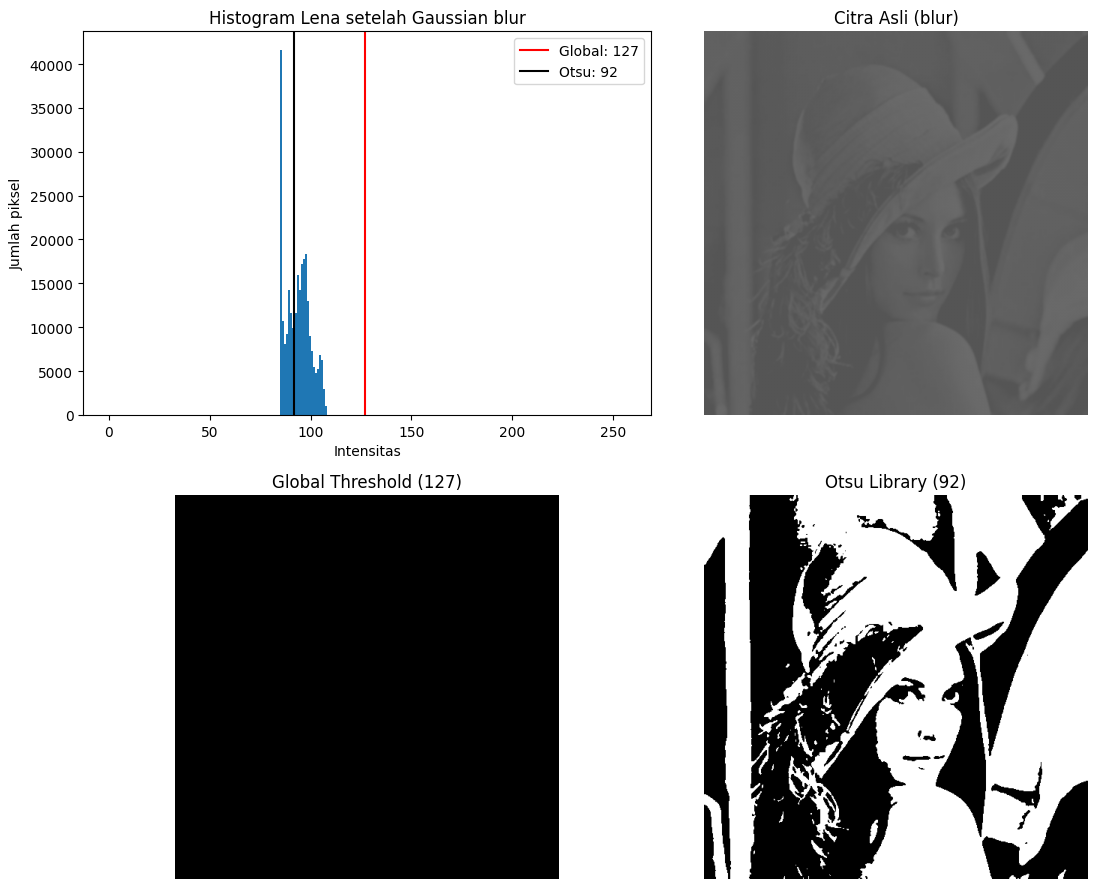

In [29]:
lena = baca_citra('lena', grayscale=True)
blur_lena = cv.GaussianBlur(lena, (5, 5), 0)
ret, global_lena = cv.threshold(blur_lena, 127, 255, cv.THRESH_BINARY)
ret2, otsu_lena_cv = cv.threshold(blur_lena, 0, 255,
                                cv.THRESH_BINARY + cv.THRESH_OTSU)

print('Threshold Otsu dengan library:', ret2)
plt.figure(figsize=(12, 9))
plt.subplot(2, 2, 1)
plt.hist(blur_lena.ravel(), 256, [0, 256])
plt.axvline(127, color='red', label='Global: 127')
plt.axvline(ret2, color='black', label=f'Otsu: {ret2:.0f}')
plt.title('Histogram Lena setelah Gaussian blur')
plt.xlabel('Intensitas')
plt.ylabel('Jumlah piksel')
plt.legend()
for i, (img, title) in enumerate(zip(
    [blur_lena, global_lena, otsu_lena_cv],
    ['Citra Asli (blur)', 'Global Threshold (127)', f'Otsu Library ({ret2:.0f})']
)):
    plt.subplot(2, 2, i + 2)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()


### C.5 Otsu sebelum dan sesudah Gaussian filtering


/tmp/ipykernel_1880/1198524609.py:19: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(source.ravel(), 256, [0, 256])


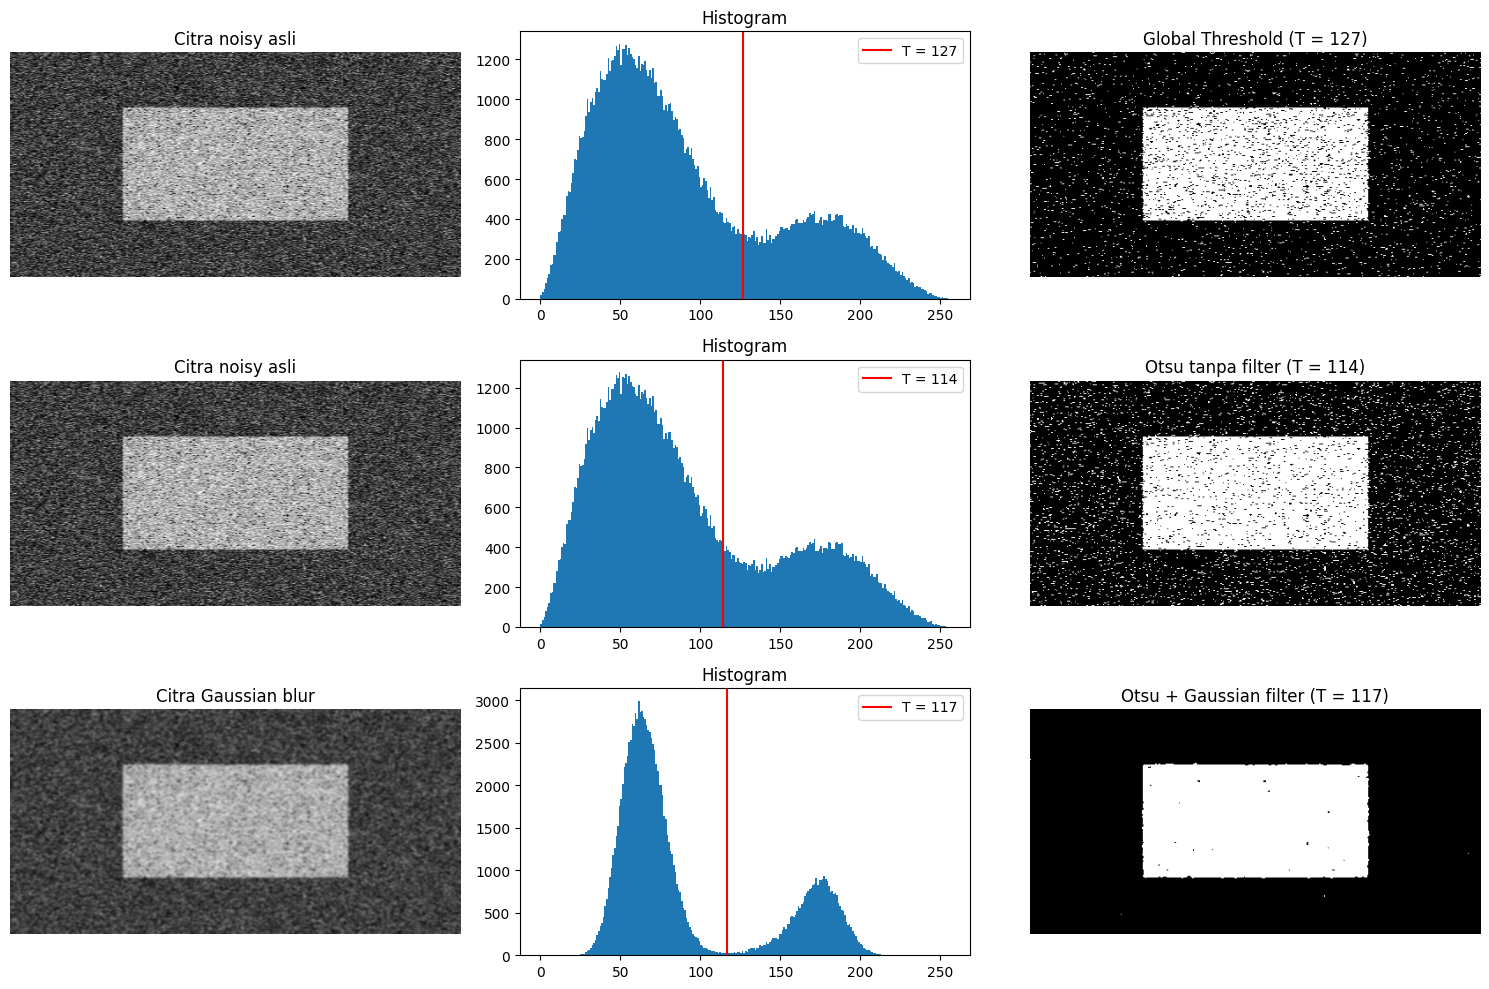

In [30]:
noisy = baca_citra('noisy', grayscale=True)
ret1, th1 = cv.threshold(noisy, 127, 255, cv.THRESH_BINARY)
ret2, th2 = cv.threshold(noisy, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
blur_noisy = cv.GaussianBlur(noisy, (5, 5), 0)
ret3, th3 = cv.threshold(blur_noisy, 0, 255,
                       cv.THRESH_BINARY + cv.THRESH_OTSU)

plt.figure(figsize=(15, 10))
for i, (source, result, threshold, name) in enumerate([
    (noisy, th1, ret1, 'Global Threshold'),
    (noisy, th2, ret2, 'Otsu tanpa filter'),
    (blur_noisy, th3, ret3, 'Otsu + Gaussian filter'),
]):
    plt.subplot(3, 3, i * 3 + 1)
    plt.imshow(source, cmap='gray', vmin=0, vmax=255)
    plt.title('Citra Gaussian blur' if i == 2 else 'Citra noisy asli')
    plt.axis('off')
    plt.subplot(3, 3, i * 3 + 2)
    plt.hist(source.ravel(), 256, [0, 256])
    plt.axvline(threshold, color='red', label=f'T = {threshold:.0f}')
    plt.title('Histogram')
    plt.legend()
    plt.subplot(3, 3, i * 3 + 3)
    plt.imshow(result, cmap='gray', vmin=0, vmax=255)
    plt.title(f'{name} (T = {threshold:.0f})')
    plt.axis('off')
plt.tight_layout()
plt.show()


## C.7 Contoh Segmentasi Warna dengan K-Means


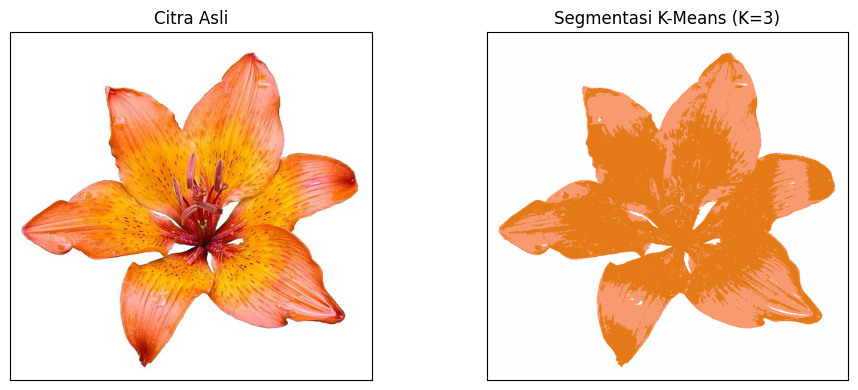

In [31]:
img = baca_citra('lily')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
Z = np.float32(img.reshape((-1, 3)))

k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

tampilkan([img, segmented_img], ['Citra Asli', 'Segmentasi K-Means (K=3)'],
          figsize=(10, 4))


## D1 nomor 3 Lima Global Threshold secara manual

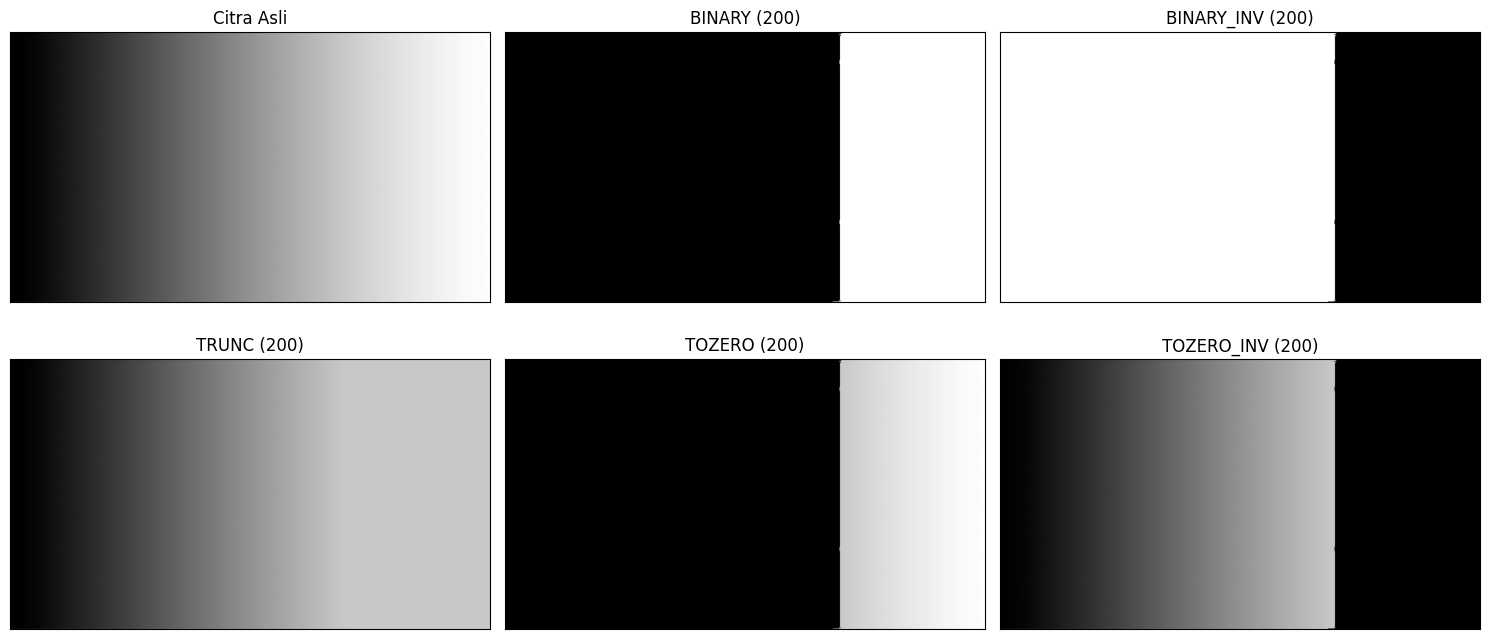

In [32]:
def global_threshold_manual(img, thresh=200, maxval=255):
    binary = np.where(img > thresh, maxval, 0).astype(np.uint8)
    binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)
    trunc = np.where(img > thresh, thresh, img).astype(np.uint8)
    tozero = np.where(img > thresh, img, 0).astype(np.uint8)
    tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)
    return [binary, binary_inv, trunc, tozero, tozero_inv]

gradient_manual = baca_citra('gradient', grayscale=True)
hasil_global_manual = global_threshold_manual(gradient_manual, thresh=200)
tampilkan([gradient_manual] + hasil_global_manual,
          ['Citra Asli', 'BINARY (200)', 'BINARY_INV (200)',
           'TRUNC (200)', 'TOZERO (200)', 'TOZERO_INV (200)'],
          rows=2, cols=3, figsize=(15, 7))


## D1 nomor 4 Adaptive Mean dan Gaussian secara manual


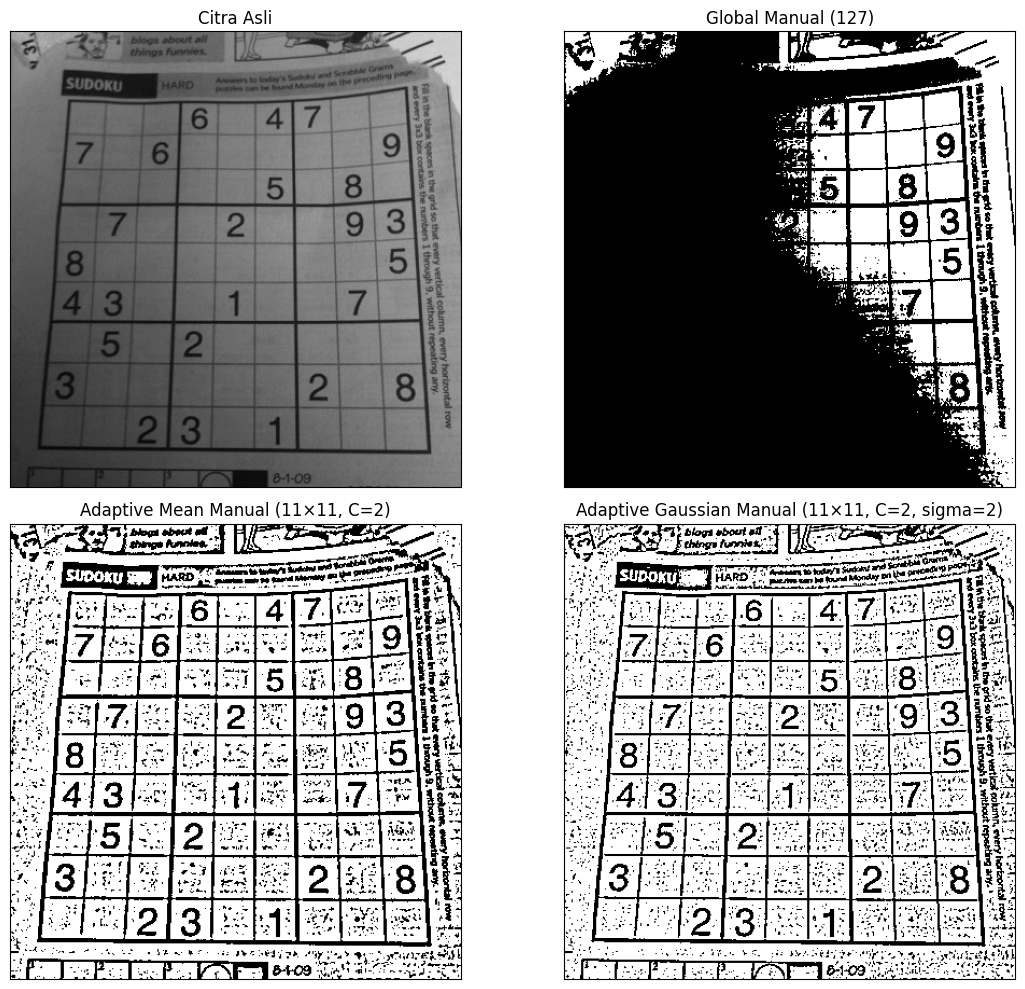

In [33]:
def filter_manual(gray, kernel):
    # Menghitung jumlah berbobot dari setiap posisi dalam jendela.
    # Array digeser untuk memproses semua piksel sekaligus dengan NumPy.
    tinggi, lebar = gray.shape
    ukuran = kernel.shape[0]
    radius = ukuran // 2
    padded = np.pad(gray.astype(np.float64), radius, mode='edge')
    hasil = np.zeros((tinggi, lebar), dtype=np.float64)
    for y in range(ukuran):
        for x in range(ukuran):
            hasil += kernel[y, x] * padded[y:y + tinggi, x:x + lebar]
    return hasil

def adaptive_threshold_manual(gray, block_size=11, C=2, sigma=2):
    if block_size < 3 or block_size % 2 == 0:
        raise ValueError('Ukuran jendela harus ganjil dan minimal 3.')
    if sigma <= 0:
        raise ValueError('Sigma harus lebih besar dari 0.')

    kernel_mean = np.ones((block_size, block_size), dtype=np.float64)
    kernel_mean /= block_size * block_size

    radius = block_size // 2
    posisi = np.arange(-radius, radius + 1)
    xx, yy = np.meshgrid(posisi, posisi)
    kernel_gaussian = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel_gaussian /= kernel_gaussian.sum()

    mean_lokal = filter_manual(gray, kernel_mean)
    gaussian_lokal = filter_manual(gray, kernel_gaussian)
    hasil_mean = np.where(gray > mean_lokal - C, 255, 0).astype(np.uint8)
    hasil_gaussian = np.where(gray > gaussian_lokal - C, 255, 0).astype(np.uint8)
    return hasil_mean, hasil_gaussian

sudoku_manual = baca_citra('sudoku', grayscale=True)
global_sudoku_manual = np.where(sudoku_manual > 127, 255, 0).astype(np.uint8)
mean_manual, gaussian_manual = adaptive_threshold_manual(
    sudoku_manual, block_size=11, C=2, sigma=2
)
tampilkan([sudoku_manual, global_sudoku_manual, mean_manual, gaussian_manual],
          ['Citra Asli', 'Global Manual (127)',
           'Adaptive Mean Manual (11×11, C=2)',
           'Adaptive Gaussian Manual (11×11, C=2, sigma=2)'],
          rows=2, cols=2, figsize=(12, 10))


global threshold memakai satu ambang untuk seluruh citra,
sehingga area gelap dan terang pada Sudoku dapat diperlakukan kurang sesuai.
Adaptive threshold menghitung ambang berdasarkan lingkungan piksel.
Gaussian memberi bobot lebih besar pada piksel di dekat pusat jendela.

## D1 nomor 5A Otsu secara manual dan perbandingan library



Threshold Otsu manual: 92
Threshold Otsu library: 92.0
Jumlah piksel hasil manual/library yang berbeda: 0


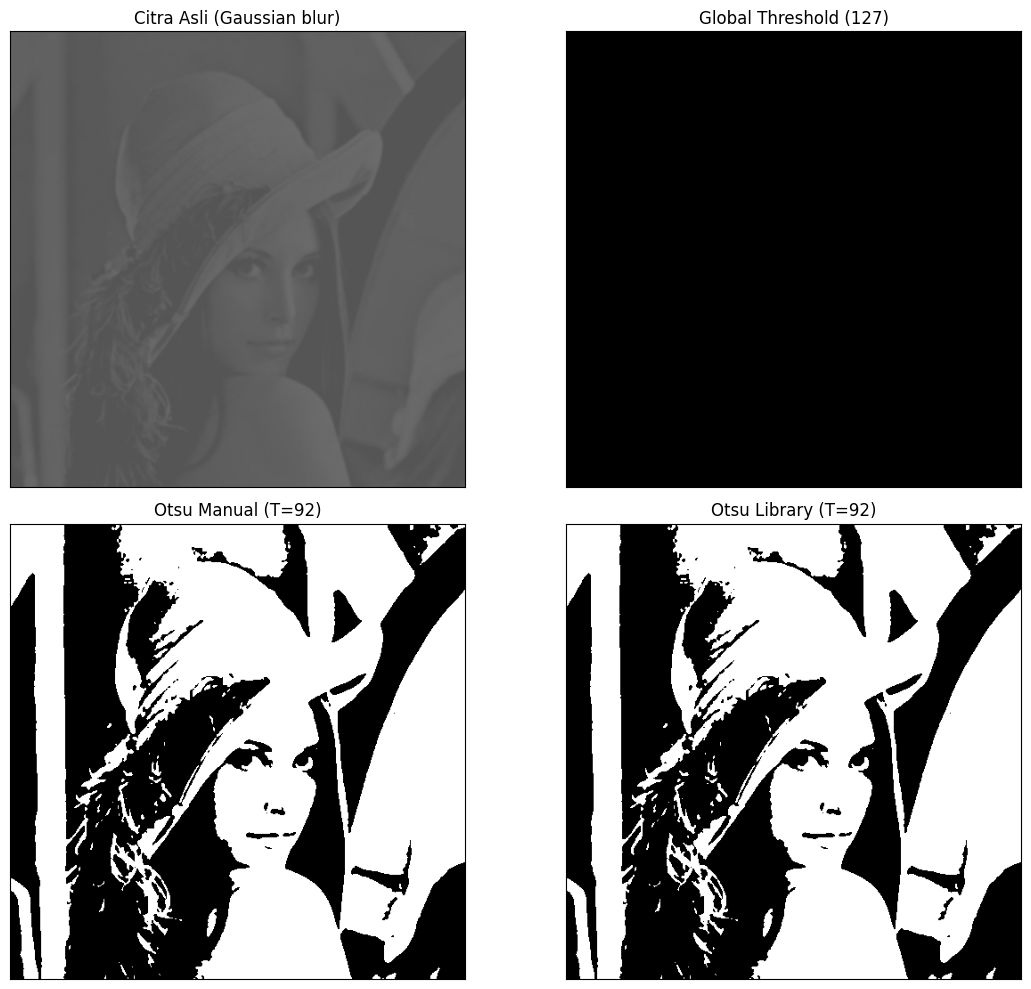

In [34]:
def otsu_manual(gray):
    pixel_number = gray.size
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    intensity_arr = np.arange(256)
    final_thresh = 0
    final_value = -1.0

    for t in range(256):
        pcb = np.sum(his[:t + 1])
        pcf = np.sum(his[t + 1:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t + 1] * his[:t + 1]) / float(pcb)
        muf = np.sum(intensity_arr[t + 1:] * his[t + 1:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = np.where(gray > final_thresh, 255, 0).astype(np.uint8)
    return final_img, final_thresh

lena_individu = baca_citra('lena', grayscale=True)
blur_lena_individu = cv.GaussianBlur(lena_individu, (5, 5), 0)
otsu_lena_manual, T_lena = otsu_manual(blur_lena_individu)
global_lena_manual = np.where(blur_lena_individu > 127, 255, 0).astype(np.uint8)
T_lena_cv, otsu_lena_library = cv.threshold(
    blur_lena_individu, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU
)

print('Threshold Otsu manual:', T_lena)
print('Threshold Otsu library:', T_lena_cv)
print('Jumlah piksel hasil manual/library yang berbeda:',
      np.count_nonzero(otsu_lena_manual != otsu_lena_library))
tampilkan([blur_lena_individu, global_lena_manual,
           otsu_lena_manual, otsu_lena_library],
          ['Citra Asli (Gaussian blur)', 'Global Threshold (127)',
           f'Otsu Manual (T={T_lena})', f'Otsu Library (T={T_lena_cv:.0f})'],
          rows=2, cols=2, figsize=(12, 10))


### Jawaban analisis histogram Lena

Pada versi low contrast yang dijelaskan modul, intensitas Lena sekitar 85–108.
Seluruh intensitas tersebut berada di bawah 127, sehingga Binary Threshold
menjadikan semua piksel 0 (hitam). Nilai ambang yang masih menampilkan pemisahan
objek perlu berada di dalam rentang intensitas citra; Otsu memilihnya melalui
pemisahan histogram. Contoh modul menunjukkan nilai sekitar 92, tetapi
nilai yang digunakan pada notebook ini dihitung dari file sebenarnya.

Sel berikut menampilkan histogram, rentang aktual, jumlah piksel putih,
serta nilai ambang yang disarankan berdasarkan hasil Otsu manual.

Rentang intensitas Lena setelah blur: 85–108
Global T=127: 0 dari 262144 piksel putih
Otsu T=92: 145128 dari 262144 piksel putih
Semua piksel ≤ 127; karena itu hasil Binary Threshold hitam seluruhnya.
Ambang yang disarankan berdasarkan histogram aktual: T = 92


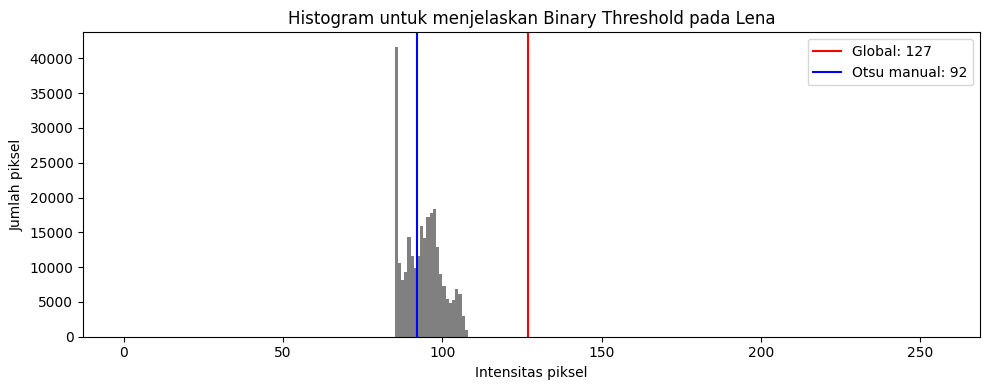

In [35]:
minimum = int(blur_lena_individu.min())
maksimum = int(blur_lena_individu.max())
putih_global = int(np.count_nonzero(global_lena_manual))
putih_otsu = int(np.count_nonzero(otsu_lena_manual))
print(f'Rentang intensitas Lena setelah blur: {minimum}–{maksimum}')
print(f'Global T=127: {putih_global} dari {blur_lena_individu.size} piksel putih')
print(f'Otsu T={T_lena}: {putih_otsu} dari {blur_lena_individu.size} piksel putih')
if maksimum <= 127:
    print('Semua piksel ≤ 127; karena itu hasil Binary Threshold hitam seluruhnya.')
else:
    print('File ini memiliki intensitas > 127; hasil global tidak hitam seluruhnya.')
print(f'Ambang yang disarankan berdasarkan histogram aktual: T = {T_lena}')

plt.figure(figsize=(10, 4))
plt.hist(blur_lena_individu.ravel(), bins=np.arange(257), color='gray')
plt.axvline(127, color='red', label='Global: 127')
plt.axvline(T_lena, color='blue', label=f'Otsu manual: {T_lena}')
plt.xlabel('Intensitas piksel')
plt.ylabel('Jumlah piksel')
plt.title('Histogram untuk menjelaskan Binary Threshold pada Lena')
plt.legend()
plt.tight_layout()
plt.show()


## D1 nomor 5B Otsu pada KTP sendiri


Threshold Otsu KTP sendiri: 139
Piksel putih global: 85.29%
Piksel putih Otsu: 84.31%


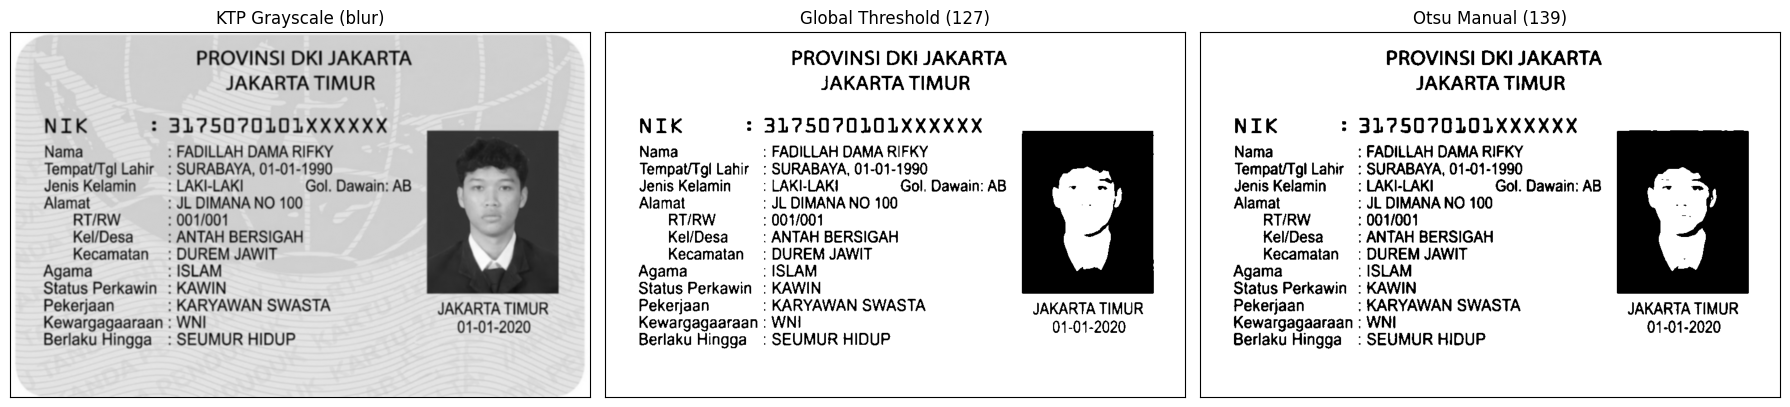

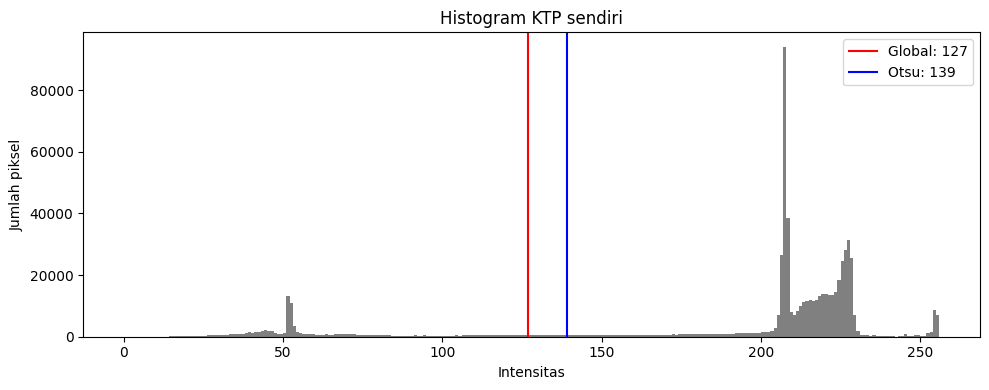

In [36]:
ktp_sendiri = baca_citra('ktp_sendiri')
ktp_gray = cv.cvtColor(ktp_sendiri, cv.COLOR_BGR2GRAY)
ktp_blur = cv.GaussianBlur(ktp_gray, (5, 5), 0)
ktp_global = np.where(ktp_blur > 127, 255, 0).astype(np.uint8)
ktp_otsu, T_ktp = otsu_manual(ktp_blur)

print('Threshold Otsu KTP sendiri:', T_ktp)
print(f'Piksel putih global: {np.mean(ktp_global == 255) * 100:.2f}%')
print(f'Piksel putih Otsu: {np.mean(ktp_otsu == 255) * 100:.2f}%')
tampilkan([ktp_blur, ktp_global, ktp_otsu],
          ['KTP Grayscale (blur)', 'Global Threshold (127)', f'Otsu Manual ({T_ktp})'],
          figsize=(18, 6))

plt.figure(figsize=(10, 4))
plt.hist(ktp_blur.ravel(), bins=np.arange(257), color='gray')
plt.axvline(127, color='red', label='Global: 127')
plt.axvline(T_ktp, color='blue', label=f'Otsu: {T_ktp}')
plt.title('Histogram KTP sendiri')
plt.xlabel('Intensitas')
plt.ylabel('Jumlah piksel')
plt.legend()
plt.tight_layout()
plt.show()


Pembahasan: pada KTP, global threshold membagi piksel dengan nilai tetap 127,
sedangkan Otsu menyesuaikan ambang terhadap distribusi intensitas KTP tersebut.
Bandingkan keterlihatan tulisan dan pola latar pada hasil yang muncul.
Otsu tidak selalu lebih baik untuk semua bagian citra, terutama jika pencahayaan
tidak merata, karena ambangnya tetap satu nilai untuk keseluruhan citra.

## D1 nomor 6A Segmentasi berbasis region pada data.coins()


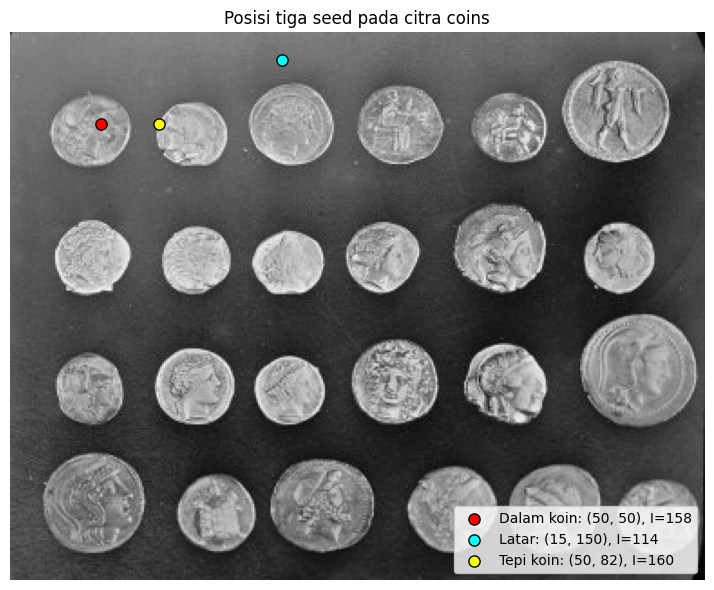

In [37]:
coins = data.coins()
seed_koin = (50, 50)
seed_latar = (15, 150)

# Cari perubahan intensitas terbesar pada sisi kanan koin pertama.
profil = coins[50, 60:90].astype(np.float64)
kolom_tepi = 60 + int(np.argmax(np.abs(np.diff(profil)))) + 1
seed_tepi = (50, kolom_tepi)
seeds = {'Dalam koin': seed_koin, 'Latar': seed_latar, 'Tepi koin': seed_tepi}
tolerances = [5, 20, 60]

plt.figure(figsize=(9, 6))
plt.imshow(coins, cmap='gray', vmin=0, vmax=255)
for (name, (row, col)), color in zip(seeds.items(), ['red', 'cyan', 'yellow']):
    plt.scatter(col, row, color=color, s=65, edgecolors='black',
                label=f'{name}: ({row}, {col}), I={coins[row, col]}')
plt.title('Posisi tiga seed pada citra coins')
plt.legend(loc='lower right')
plt.axis('off')
plt.tight_layout()
plt.show()


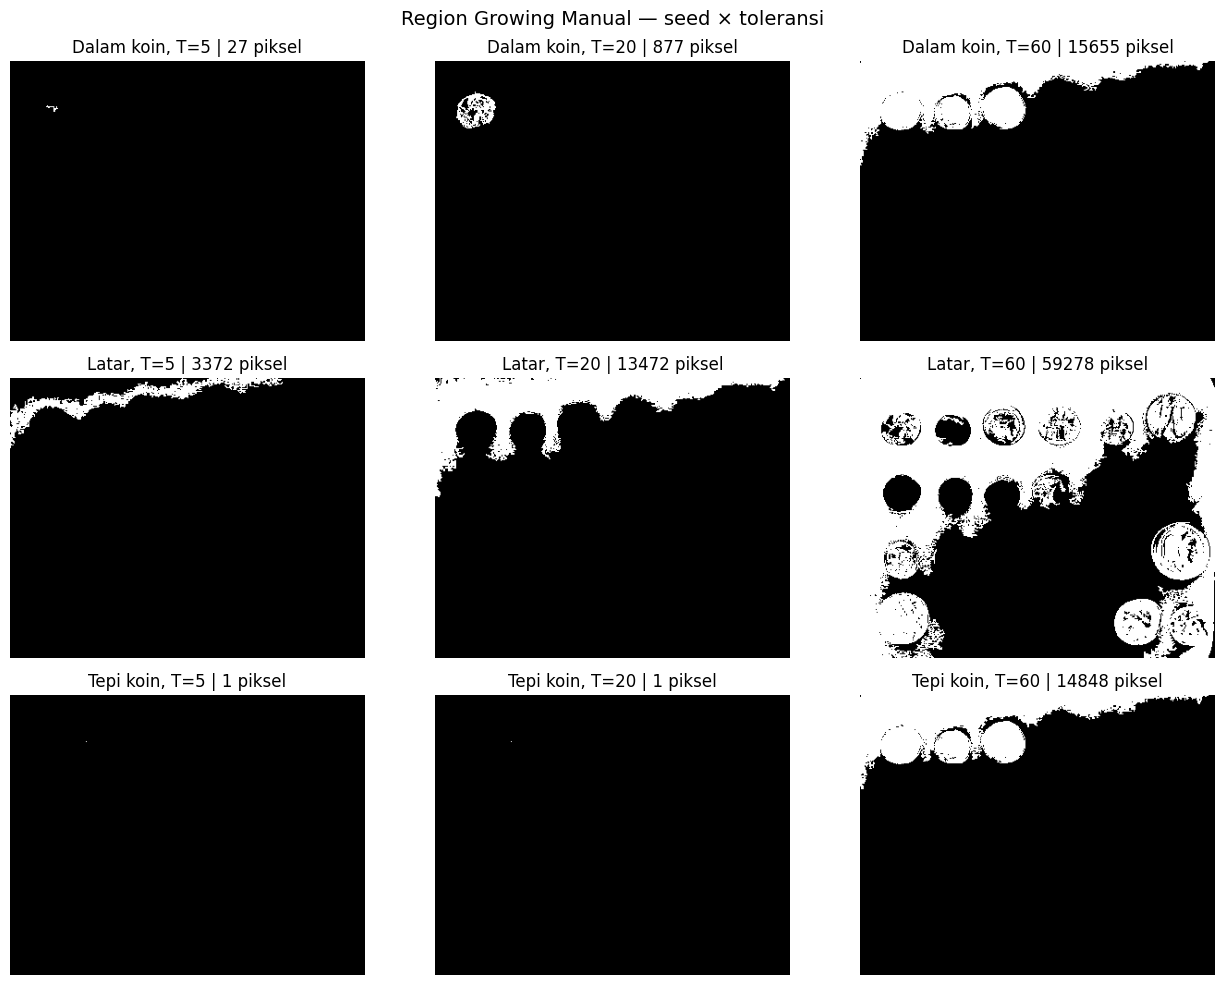

In [38]:
def region_growing_manual(gray, seed, T):
    tinggi, lebar = gray.shape
    mask = np.zeros(gray.shape, dtype=bool)
    visited = np.zeros(gray.shape, dtype=bool)
    seed_value = int(gray[seed])
    antrian = deque([seed])
    mask[seed] = True
    visited[seed] = True

    while antrian:
        row, col = antrian.popleft()
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nr, nc = row + dr, col + dc
            if not (0 <= nr < tinggi and 0 <= nc < lebar):
                continue
            if visited[nr, nc]:
                continue
            visited[nr, nc] = True
            if abs(int(gray[nr, nc]) - seed_value) <= T:
                mask[nr, nc] = True
                antrian.append((nr, nc))
    return mask

hasil_region = {}
plt.figure(figsize=(13, 10))
for i, (name, seed) in enumerate(seeds.items()):
    for j, T in enumerate(tolerances):
        mask = region_growing_manual(coins, seed, T)
        hasil_region[(name, T)] = mask
        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(mask, cmap='gray', vmin=0, vmax=1)
        plt.title(f'{name}, T={T} | {mask.sum()} piksel')
        plt.axis('off')
plt.suptitle('Region Growing Manual — seed × toleransi', fontsize=14)
plt.tight_layout()
plt.show()


## D1 nomor 6B Segmentasi dengan skimage.segmentation.flood()


Dalam koin   T= 5:     27 piksel; perbedaan dengan manual = 0
Dalam koin   T=20:    877 piksel; perbedaan dengan manual = 0
Dalam koin   T=60:  15655 piksel; perbedaan dengan manual = 0
Latar        T= 5:   3372 piksel; perbedaan dengan manual = 0
Latar        T=20:  13472 piksel; perbedaan dengan manual = 0
Latar        T=60:  59278 piksel; perbedaan dengan manual = 0
Tepi koin    T= 5:      1 piksel; perbedaan dengan manual = 0
Tepi koin    T=20:      1 piksel; perbedaan dengan manual = 0
Tepi koin    T=60:  14848 piksel; perbedaan dengan manual = 0


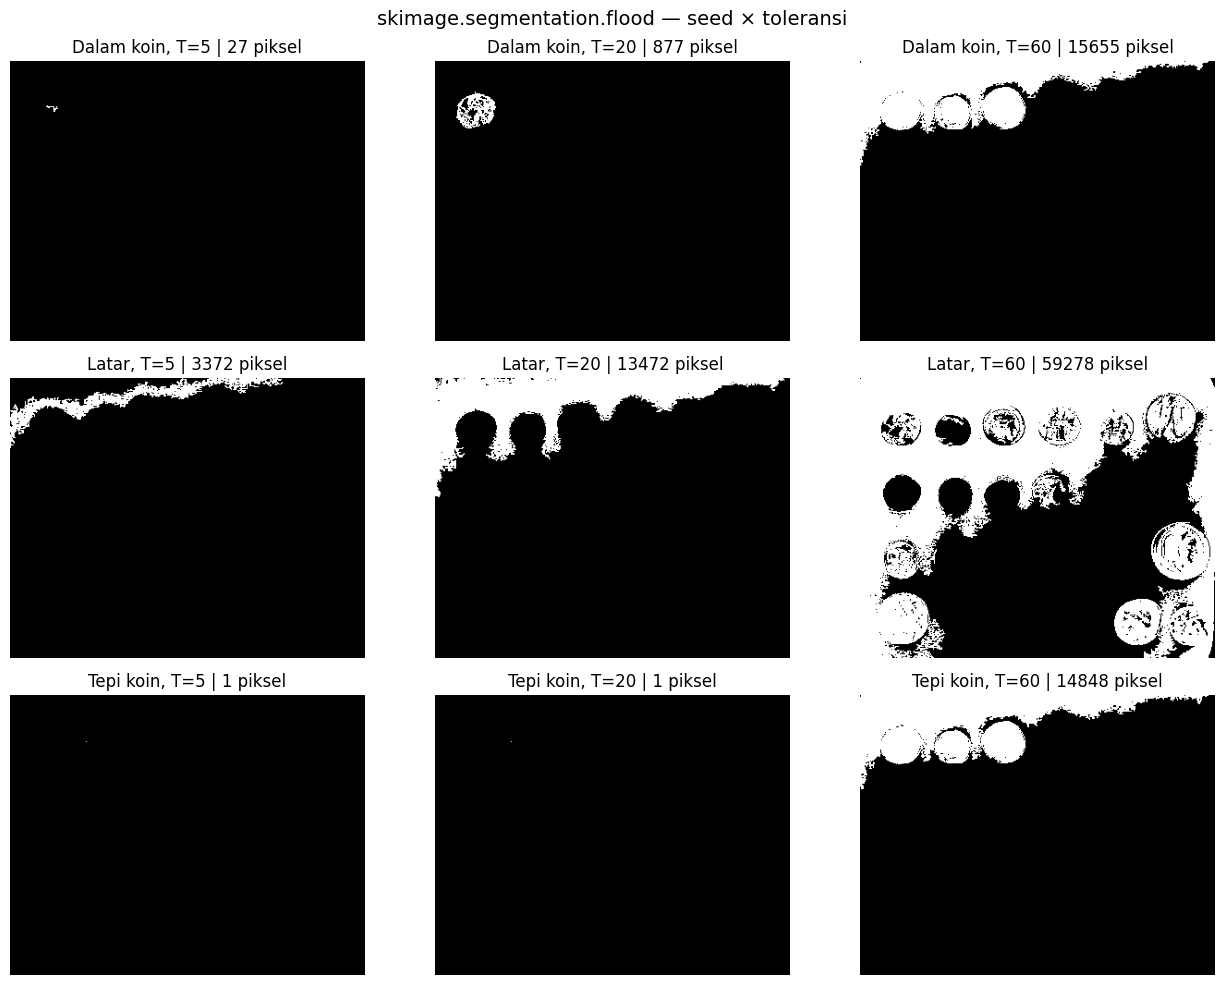

In [39]:
plt.figure(figsize=(13, 10))
for i, (name, seed) in enumerate(seeds.items()):
    for j, T in enumerate(tolerances):
        mask = flood(coins, seed_point=seed, tolerance=T, connectivity=1)
        berbeda = np.count_nonzero(mask != hasil_region[(name, T)])
        print(f'{name:12s} T={T:2d}: {mask.sum():6d} piksel; '
              f'perbedaan dengan manual = {berbeda}')
        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(mask, cmap='gray', vmin=0, vmax=1)
        plt.title(f'{name}, T={T} | {mask.sum()} piksel')
        plt.axis('off')
plt.suptitle('skimage.segmentation.flood — seed × toleransi', fontsize=14)
plt.tight_layout()
plt.show()


Pembahasan: T kecil membatasi pertumbuhan pada intensitas yang dekat
dengan seed, sehingga region dapat berupa bercak kecil. T besar menerima
lebih banyak intensitas dan dapat membuat region meluas ke latar atau objek lain.
Seed di latar menumbuhkan region latar; seed di tepi lebih sensitif terhadap
perubahan intensitas pada batas koin. Kedua implementasi memakai kriteria
dan konektivitas sama sehingga mask seharusnya sama.

## D1 nomor 7 Segmentasi warna biru pada KTP


Centroid HSV: [[100  34 244]
 [105  11  46]
 [  3 129 182]]
Cluster biru: [0]
Piksel biru menurut HSV: 237246 (74.64%)


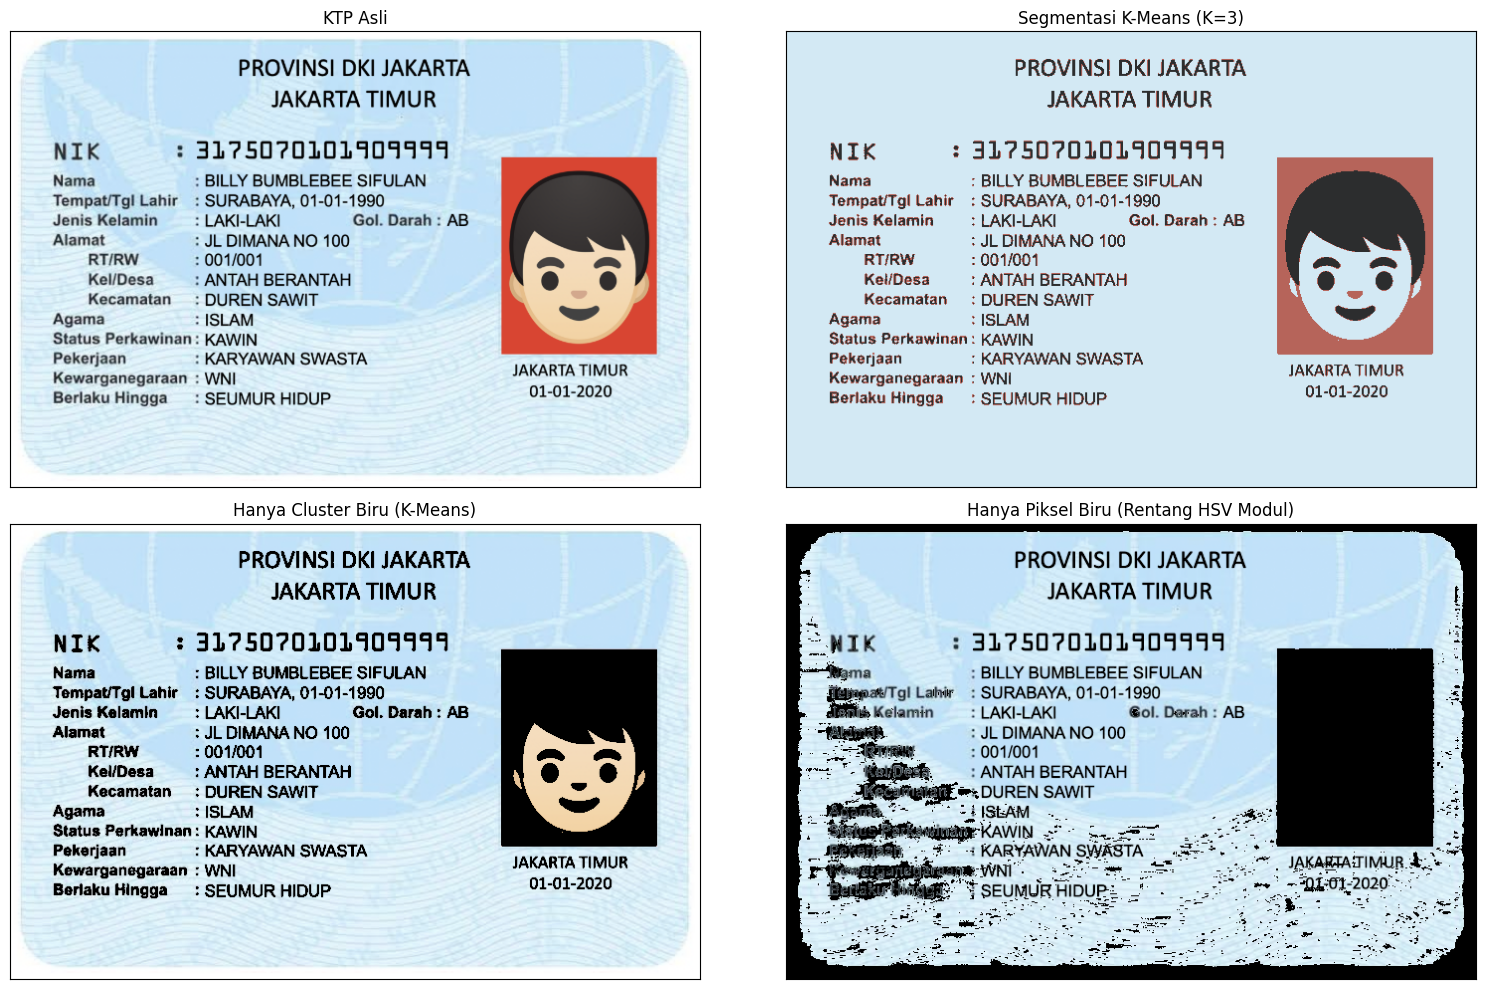

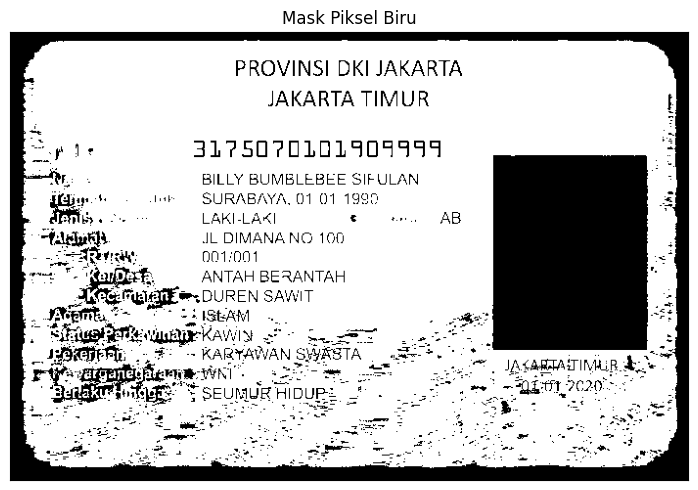

In [40]:
ktp_warna_bgr = baca_citra('ktp_fulan')
ktp_warna_rgb = cv.cvtColor(ktp_warna_bgr, cv.COLOR_BGR2RGB)
Z = np.float32(ktp_warna_rgb.reshape((-1, 3)))

kmeans_ktp = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_ktp = kmeans_ktp.fit_predict(Z).reshape(ktp_warna_rgb.shape[:2])
centers_rgb = np.uint8(kmeans_ktp.cluster_centers_)
centers_hsv = cv.cvtColor(centers_rgb.reshape(1, -1, 3),
                          cv.COLOR_RGB2HSV).reshape(-1, 3)
Hc, Sc, Vc = centers_hsv[:, 0], centers_hsv[:, 1], centers_hsv[:, 2]
cluster_biru = np.where((Hc >= 85) & (Hc <= 130) & (Sc >= 25) & (Vc >= 40))[0]
mask_cluster_biru = np.isin(labels_ktp, cluster_biru)
biru_kmeans = np.zeros_like(ktp_warna_rgb)
biru_kmeans[mask_cluster_biru] = ktp_warna_rgb[mask_cluster_biru]
ktp_segmented = centers_rgb[labels_ktp]

# Rentang HSV persis seperti petunjuk pada modul.
hsv = cv.cvtColor(ktp_warna_bgr, cv.COLOR_BGR2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))
biru_hsv = np.zeros_like(ktp_warna_rgb)
biru_hsv[kelompok_biru] = ktp_warna_rgb[kelompok_biru]
mask_biru_hsv = np.zeros(H.shape, dtype=np.uint8)
mask_biru_hsv[kelompok_biru] = 255

print('Centroid HSV:', centers_hsv)
print('Cluster biru:', cluster_biru.tolist())
if cluster_biru.size == 0:
    print('Tidak ada centroid K=3 yang masuk rentang biru; '
          'lihat hasil pemilihan piksel HSV langsung.')
print(f'Piksel biru menurut HSV: {len(kelompok_biru[0])} '
      f'({len(kelompok_biru[0]) / H.size * 100:.2f}%)')
tampilkan([ktp_warna_rgb, ktp_segmented, biru_kmeans, biru_hsv],
          ['KTP Asli', 'Segmentasi K-Means (K=3)',
           'Hanya Cluster Biru (K-Means)', 'Hanya Piksel Biru (Rentang HSV Modul)'],
          rows=2, cols=2, figsize=(16, 10))
tampilkan([mask_biru_hsv], ['Mask Piksel Biru'], figsize=(8, 5))


Pembahasan: K-Means mengganti banyak warna menjadi beberapa centroid.
Satu cluster dapat mencakup variasi warna yang luas, sehingga pemilihan cluster
biru dapat membawa piksel yang tidak persis berada pada rentang HSV.
Pemilihan HSV langsung mempertahankan warna asli hanya pada piksel yang
memenuhi rentang yang diberikan modul; piksel lainnya menjadi hitam.